# Quantitative Signal Validation: Daily Lower-Wick Overlap vs. Random Noise
**Assets:** `BTCUSDT`, `ETHUSDT`, `SOLUSDT` (Daily `1D` Bars) &nbsp;|&nbsp; **Sample:** January 2021 – November 2026 ($2,141$ daily observations per asset)

---

## Signal Setup
We test whether placing a resting **Limit Buy** order at the midpoint of two consecutive daily candles' overlapping lower wicks generates statistically significant excess return (*Alpha*) over random entries sharing the exact same stop and target.

For daily candle $t$, let $B_t = \min(O_t, C_t)$ denote the bottom of the candle body. The **lower wick** is the interval $W_t = [L_t, B_t]$, with relative wick ratio $w_t = \frac{B_t - L_t}{H_t - L_t}$. Given two consecutive candles $t-1$ and $t$, their **Overlap Zone** is:

$$\mathcal{Z}_t = W_{t-1} \cap W_t = \big[\max(L_{t-1}, L_t),\ \min(B_{t-1}, B_t)\big] = \big[\text{Zone}_{\text{low}, t},\ \text{Zone}_{\text{high}, t}\big]$$

A setup triggers at the close of day $t$ if:
1. **Non-empty intersection:** $\text{Zone}_{\text{high}, t} > \text{Zone}_{\text{low}, t}$
2. **Meaningful rejection wicks:** $w_{t-1} \ge 0.25$ and $w_t \ge 0.25$ (each lower wick is at least $25\%$ of the candle's `High–Low` range).

A resting **Limit Buy** order is placed at the midpoint $P_{\text{entry}, t} = \frac{\text{Zone}_{\text{low}, t} + \text{Zone}_{\text{high}, t}}{2}$ for up to $\tau = 3$ days.


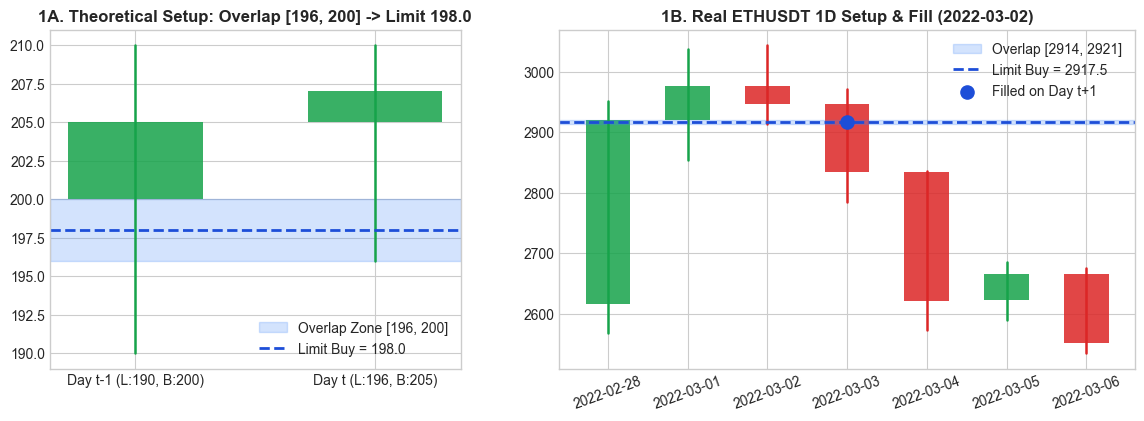

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde, norm

plt.style.use('seaborn-v0_8-whitegrid')
ASSETS = ['BTCUSDT', 'ETHUSDT', 'SOLUSDT']
COLORS = {'BTCUSDT': '#d97706', 'ETHUSDT': '#2563eb', 'SOLUSDT': '#0d9488'}
DATA = {s: pd.read_csv(f"{s.lower()}_1d_2021.csv", index_col='Date', parse_dates=True) for s in ASSETS}

def wick_overlap(df, min_w=0.25):
    O, H, L, C = df['Open'].values, df['High'].values, df['Low'].values, df['Close'].values
    b = np.minimum(O, C)
    pb, pL, pH = np.roll(b, 1), np.roll(L, 1), np.roll(H, 1)
    zl, zh = np.maximum(pL, L), np.minimum(pb, b)
    w1, w2 = (pb - pL) / np.maximum(pH - pL, 1e-8), (b - L) / np.maximum(H - L, 1e-8)
    ok = (pb > pL) & (b > L) & (w1 >= min_w) & (w2 >= min_w) & (zh > zl)
    ok[0] = False
    return df.assign(zl=np.where(ok, zl, np.nan), zh=np.where(ok, zh, np.nan),
                     entry=np.where(ok, 0.5 * (zl + zh), np.nan), ok=ok)

def plot_candles(ax, d, title):
    for k, (_, r) in enumerate(d.iterrows()):
        c = '#16a34a' if r['Close'] >= r['Open'] else '#dc2626'
        ax.plot([k, k], [r['Low'], r['High']], color=c, lw=1.8)
        ax.add_patch(plt.Rectangle((k - 0.28, min(r['Open'], r['Close'])), 0.56,
                     max(abs(r['Close'] - r['Open']), (r['High'] - r['Low']) * 0.02), facecolor=c, alpha=0.85))
    ax.set_title(title, fontweight='bold')

theo = wick_overlap(pd.DataFrame({'Open':[200.,205.], 'High':[210.,210.], 'Low':[190.,196.], 'Close':[205.,207.]}, index=['Day t-1','Day t']))
eth = wick_overlap(DATA['ETHUSDT'])
idx = [i for i in np.where(eth['ok'])[0][100:-5] if eth['Low'].iloc[i+1] <= eth['entry'].iloc[i] <= eth['Open'].iloc[i+1]][0]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [1, 1.4]})
plot_candles(ax[0], theo, "1A. Theoretical Setup: Overlap [196, 200] -> Limit 198.0")
ax[0].axhspan(196, 200, color='#3b82f6', alpha=0.22, label='Overlap Zone [196, 200]')
ax[0].axhline(198, color='#1d4ed8', ls='--', lw=2, label='Limit Buy = 198.0')
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(['Day t-1 (L:190, B:200)', 'Day t (L:196, B:205)']); ax[0].legend()

zl, zh, ep = eth[['zl', 'zh', 'entry']].iloc[idx]
plot_candles(ax[1], eth.iloc[idx-2:idx+5], f"1B. Real ETHUSDT 1D Setup & Fill ({eth.index[idx].date()})")
ax[1].axhspan(zl, zh, color='#3b82f6', alpha=0.22, label=f'Overlap [{zl:.0f}, {zh:.0f}]')
ax[1].axhline(ep, color='#1d4ed8', ls='--', lw=2, label=f'Limit Buy = {ep:.1f}')
ax[1].scatter([3], [ep], color='#1d4ed8', s=90, zorder=5, label='Filled on Day t+1')
ax[1].set_xticks(range(7)); ax[1].set_xticklabels([d.strftime('%Y-%m-%d') for d in eth.index[idx-2:idx+5]], rotation=20); ax[1].legend()
plt.show()


---

## Track Record
**Methodology (pure event study via `eval_trades`):**  
Our goal is to validate the statistical predictive power of the **signal itself** every time it appears, not the trajectory of a capital-constrained portfolio. Each entry is therefore evaluated **independently (standalone)**:
- When a valid setup triggers on day $t$ and its limit order is filled on day $fb \in [t+1, t+3]$, we track that specific trade forward until day $k$ when it touches either the Stop Loss ($-4\%$) or the Take Profit ($+6\%$).
- If another two-candle wick overlap forms while a previous trade is still open, the new signal is also evaluated independently on its own barrier path.
- Every filled trade $i \in \{1, \dots, N\}$ is measured in **risk units ($1R = s = 4\%$ Stop Loss)** with binary payoff $R_i \in \{-1.0,\ +RR\}$, eliminating compounding distortion.

For a given Risk:Reward ratio $RR$ (baseline $RR = 1.5$, Target $= +6\%$), the **Break-Even Win Rate ($p_{\text{BE}}$)**, **Expected Value ($E[R]$)**, and **Profit Factor ($\text{PF}$)** are:

$$p_{\text{BE}} = \frac{1}{1 + RR}, \qquad E[R] = \hat{p} \cdot RR - (1 - \hat{p}) = (1 + RR)\,(\hat{p} - p_{\text{BE}}), \qquad \text{PF} = \frac{\hat{p} \cdot RR}{1 - \hat{p}}$$


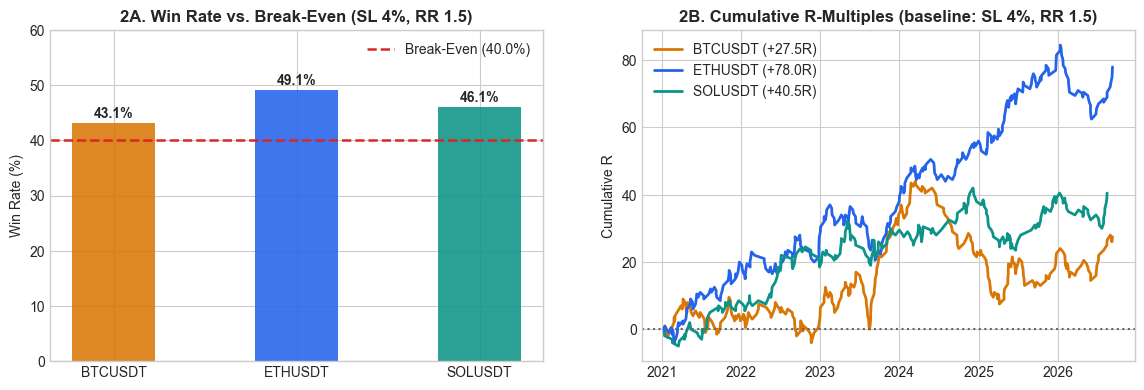

,Signals,Fills,Fill Rate,Win Rate,Break-Even,WR Edge,E[R] / Trade,Total R,Profit Factor
Asset,,,,,,,,,
BTCUSDT,444,350,78.8%,43.14%,40.0%,+3.14%,+0.0786 R,+27.5 R,1.14
ETHUSDT,459,342,74.5%,49.12%,40.0%,+9.12%,+0.2281 R,+78.0 R,1.45
SOLUSDT,366,267,73.0%,46.07%,40.0%,+6.07%,+0.1517 R,+40.5 R,1.28


In [2]:
SL, RR = 0.04, 1.5
BE_WR = 1 / (1 + RR)

def eval_trades(df, sl=SL, rr=RR, min_w=0.25, ttl=3, hold=60):
    d = wick_overlap(df, min_w)
    O, H, L, C, ep_arr = d['Open'].values, d['High'].values, d['Low'].values, d['Close'].values, d['entry'].values
    rows = []
    for i in np.where(d['ok'].values)[0]:
        if i + ttl >= len(d) - hold: continue
        ep = ep_arr[i]
        fills = [b for b in range(i + 1, i + 1 + ttl) if L[b] <= ep <= O[b]]
        if not fills: continue
        fb, sl_p, tp_p = fills[0], ep * (1 - sl), ep * (1 + sl * rr)
        for k in range(fb, fb + hold):
            if L[k] <= sl_p: rows.append((d.index[fb], -1.0, -sl * 100, (C[i] - ep) / C[i])); break
            if H[k] >= tp_p: rows.append((d.index[fb], float(rr), rr * sl * 100, (C[i] - ep) / C[i])); break
    return pd.DataFrame(rows, columns=['date', 'R', 'ret', 'pb']), int(d['ok'].sum())

TRADES, summary = {}, []
for s in ASSETS:
    tdf, n_sig = eval_trades(DATA[s])
    TRADES[s] = tdf
    wr = (tdf['R'] > 0).mean()
    summary.append({'Asset': s, 'Signals': n_sig, 'Fills': len(tdf), 'Fill Rate': f"{len(tdf)/n_sig*100:.1f}%",
                    'Win Rate': f"{wr*100:.2f}%", 'Break-Even': f"{BE_WR*100:.1f}%", 'WR Edge': f"{(wr-BE_WR)*100:+.2f}%",
                    'E[R] / Trade': f"{tdf['R'].mean():+.4f} R", 'Total R': f"{tdf['R'].sum():+.1f} R",
                    'Profit Factor': f"{(wr * RR) / (1 - wr):.2f}"})

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
wrs = [(TRADES[s]['R'] > 0).mean() * 100 for s in ASSETS]
bars = ax[0].bar(ASSETS, wrs, width=0.45, color=[COLORS[s] for s in ASSETS], alpha=0.88)
ax[0].axhline(BE_WR * 100, color='#dc2626', ls='--', lw=1.8, label=f'Break-Even ({BE_WR*100:.1f}%)')
for b, w in zip(bars, wrs): ax[0].text(b.get_x() + b.get_width()/2, w + 1, f"{w:.1f}%", ha='center', fontweight='bold')
ax[0].set_ylim(0, 60); ax[0].set_ylabel("Win Rate (%)"); ax[0].set_title(f"2A. Win Rate vs. Break-Even (SL {int(SL*100)}%, RR {RR})", fontweight='bold'); ax[0].legend()

for s in ASSETS:
    ax[1].plot(TRADES[s]['date'], TRADES[s]['R'].cumsum(), color=COLORS[s], lw=2, label=f"{s} ({TRADES[s]['R'].sum():+.1f}R)")
ax[1].axhline(0, color='#666666', ls=':'); ax[1].set_title(f"2B. Cumulative R-Multiples (baseline: SL {int(SL*100)}%, RR {RR})", fontweight='bold')
ax[1].set_ylabel("Cumulative R"); ax[1].legend()
plt.show()
pd.DataFrame(summary).set_index('Asset')


---

## Sensitivity
To verify that performance is not an artifact of a single parameter choice, we evaluate the signal across $RR \in \{1.0,\ 1.5,\ 2.0,\ 2.5,\ 3.0\}$ and $s \in \{3\%,\ 4\%,\ 5\%\}$ against a **Random Limit Benchmark** ($H_{0,\text{limit}}$, random limit buy orders placed at the same median pullback depth below the close).

Each cell reports the standardized **$z$-score** (number of standard errors above random noise) and the corresponding one-sided **$p$-value** ($p = 1 - \Phi(z)$, where $*$ denotes $p < 0.05$):

$$z(s, RR) = \frac{E[R]_{\text{signal}} - E[R]_{H_0,\text{limit}}}{\sigma_{H_0} / \sqrt{N}}, \qquad z \ge 1.65 \iff p \le 0.05^*$$


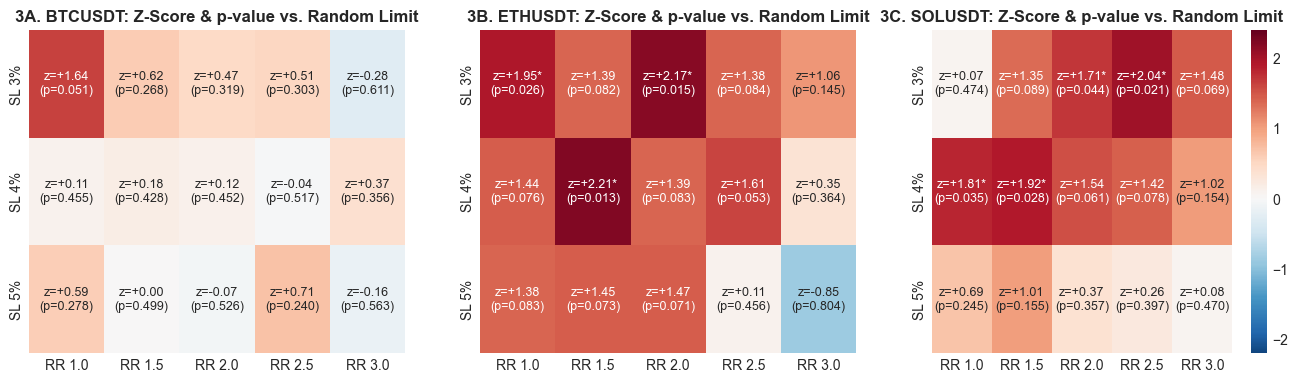

In [3]:
def random_limit_pool(df, sl, rr, pb, ttl=3, hold=60):
    O, H, L, C = df['Open'].values, df['High'].values, df['Low'].values, df['Close'].values
    out = []
    for j in range(1, len(df) - hold - ttl):
        ep = C[j] * (1 - pb)
        fills = [b for b in range(j + 1, j + 1 + ttl) if L[b] <= ep <= O[b]]
        if not fills: continue
        fb, sl_p, tp_p = fills[0], ep * (1 - sl), ep * (1 + sl * rr)
        for k in range(fb, fb + hold):
            if L[k] <= sl_p: out.append(-1.0); break
            if H[k] >= tp_p: out.append(float(rr)); break
    return np.array(out)

sl_grid, rr_grid = [0.03, 0.04, 0.05], [1.0, 1.5, 2.0, 2.5, 3.0]
fig, ax = plt.subplots(1, 3, figsize=(16.5, 4.2))

for k, s in enumerate(ASSETS):
    z_mat = np.zeros((len(sl_grid), len(rr_grid)))
    labels = np.empty_like(z_mat, dtype=object)
    for i, sl in enumerate(sl_grid):
        for j, rr in enumerate(rr_grid):
            tdf, _ = eval_trades(DATA[s], sl, rr)
            pool = random_limit_pool(DATA[s], sl, rr, tdf['pb'].median())
            z = (tdf['R'].mean() - pool.mean()) / (pool.std() / np.sqrt(len(tdf)))
            p = 1.0 - norm.cdf(z)
            star = "**" if p < 0.01 else ("*" if p < 0.05 else "")
            z_mat[i, j], labels[i, j] = z, f"z={z:+.2f}{star}\n(p={p:.3f})"
    sns.heatmap(z_mat, annot=labels, fmt="", cmap="RdBu_r", center=0, vmin=-2.2, vmax=2.4,
                xticklabels=[f"RR {r}" for r in rr_grid], yticklabels=[f"SL {int(x*100)}%" for x in sl_grid],
                cbar=(k == 2), annot_kws={'size': 9}, ax=ax[k])
    ax[k].set_title(f"3{chr(65+k)}. {s}: Z-Score & p-value vs. Random Limit", fontweight='bold')
plt.show()


---

## Validation
We conduct two statistical tests to separate genuine **Signal Alpha** from **Random Pullback Noise** and **Underlying Market Drift**:

1. **Monte Carlo Permutation Test ($H_{0,\text{limit}}$, Top Row):**  
   We simulate $M = 2,000$ random limit-entry portfolios of size $N$ with identical stop ($4\%$) and target ($6\%$). The empirical one-sided $p$-value is the fraction of random portfolios that match or exceed our signal's $E[R]$:

   $$p\text{-value} = \frac{1}{M}\sum_{m=1}^M \mathbb{I}\!\left(\bar{R}_{H_0}^{(m)} \ge E[R]_{\text{signal}}\right)$$

2. **Monthly Time-Series OLS Regression (Bottom Row):**  
   Because individual barrier trades have binary outcomes ($-4\%$ or $+6\%$), we aggregate strategy returns into **continuous monthly returns ($R_{\text{strat}, m}$)** and regress them against the **monthly return of the underlying asset ($R_{\text{asset}, m}$)** across all calendar months ($2021\text{–}2026$):

   $$R_{\text{strat}, m} = \alpha + \beta \cdot R_{\text{asset}, m} + \varepsilon_m$$

   Here, $\beta \cdot \bar{R}_{\text{asset}}$ measures the return explained by passive market drift, while the intercept **$\alpha$ (Monthly Alpha)** isolates the strategy's excess return at zero market drift ($R_{\text{asset}, m} = 0$).


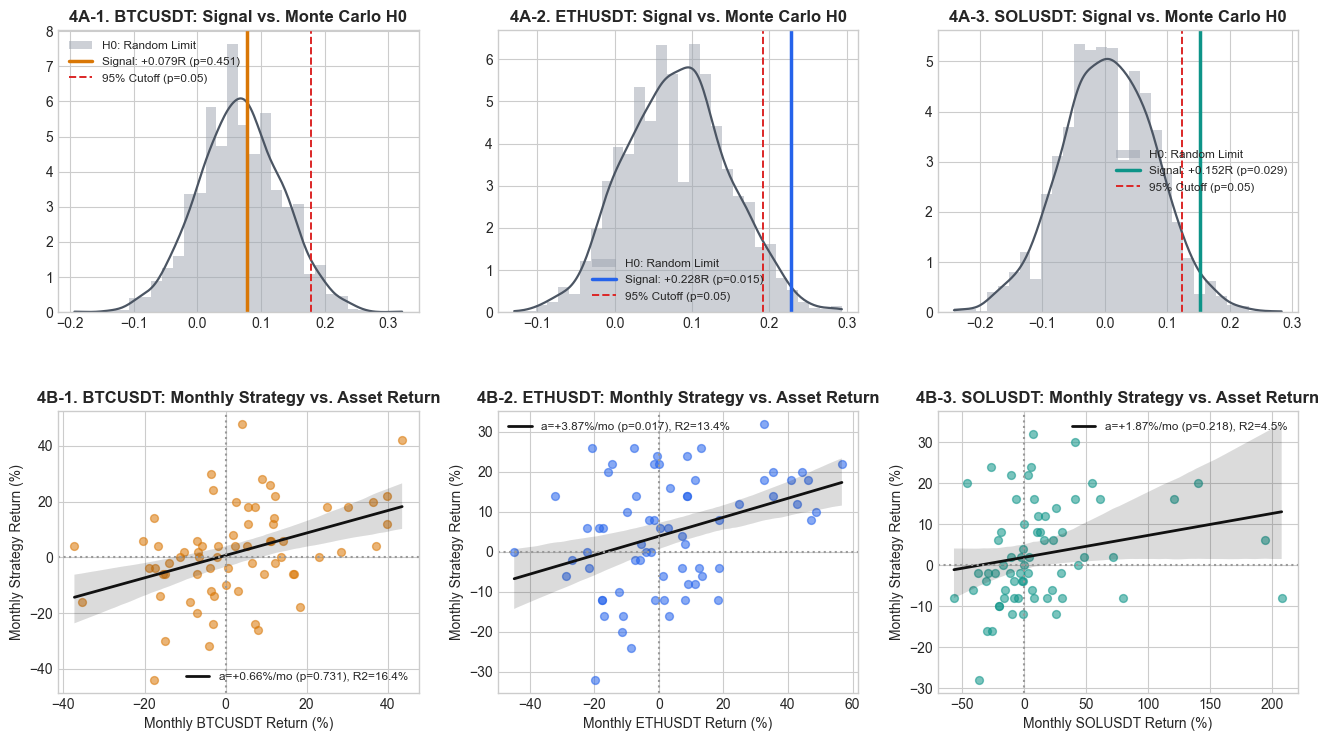

,Sig E[R],RndLim E[R],MC z-score,MC p-value,Mean Ret/Mo,Monthly Alpha (a),Drift Explained/Mo,Beta,R2 (Drift)
Asset,,,,,,,,,
BTCUSDT,+0.079R,+0.067R,+0.18,0.4505,+1.76%,"+0.66% (t=+0.34, p=0.731)",+1.11%,0.40,16.4%
ETHUSDT,+0.228R,+0.081R,+2.22,0.0155,+4.65%,"+3.87% (t=+2.38, p=0.017)",+0.78%,0.24,13.4%
SOLUSDT,+0.152R,+0.006R,+1.94,0.0290,+2.54%,"+1.87% (t=+1.23, p=0.218)",+0.67%,0.05,4.5%


In [4]:
rng = np.random.default_rng(42)
rows = []
fig, ax = plt.subplots(2, 3, figsize=(16, 8.6), gridspec_kw={'hspace': 0.35, 'wspace': 0.22})

for k, s in enumerate(ASSETS):
    tdf = TRADES[s]
    ev = tdf['R'].mean()
    pool = random_limit_pool(DATA[s], SL, RR, tdf['pb'].median())
    mc = np.array([rng.choice(pool, size=len(tdf), replace=True).mean() for _ in range(2000)])
    z_mc, p_mc = (ev - mc.mean()) / mc.std(), (mc >= ev).mean()

    m_df = pd.concat([tdf.set_index('date')['ret'].resample('M').sum().rename('y'),
                      DATA[s]['Close'].resample('M').last().pct_change().mul(100).rename('x')], axis=1).dropna()
    y, x = m_df['y'].values, m_df['x'].values
    X = np.column_stack([np.ones(len(y)), x])
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    res = y - X @ b
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X) * np.var(res, ddof=2)))
    t_a, p_a = b[0] / se[0], 2 * (1 - norm.cdf(abs(b[0] / se[0])))
    r2 = 1 - np.var(res) / np.var(y)

    rows.append({'Asset': s, 'Sig E[R]': f"{ev:+.3f}R", 'RndLim E[R]': f"{mc.mean():+.3f}R",
                 'MC z-score': f"{z_mc:+.2f}", 'MC p-value': f"{p_mc:.4f}", 'Mean Ret/Mo': f"{y.mean():+.2f}%",
                 'Monthly Alpha (a)': f"{b[0]:+.2f}% (t={t_a:+.2f}, p={p_a:.3f})",
                 'Drift Explained/Mo': f"{y.mean() - b[0]:+.2f}%", 'Beta': f"{b[1]:.2f}", 'R2 (Drift)': f"{r2*100:.1f}%"})

    ax[0, k].hist(mc, bins=30, density=True, color='#9ca3af', alpha=0.5, label='H0: Random Limit')
    xs = np.linspace(mc.min(), mc.max(), 200)
    ax[0, k].plot(xs, gaussian_kde(mc)(xs), color='#4b5563', lw=1.6)
    ax[0, k].axvline(ev, color=COLORS[s], lw=2.5, label=f"Signal: {ev:+.3f}R (p={p_mc:.3f})")
    ax[0, k].axvline(np.percentile(mc, 95), color='#dc2626', ls='--', lw=1.4, label='95% Cutoff (p=0.05)')
    ax[0, k].set_title(f"4A-{k+1}. {s}: Signal vs. Monte Carlo H0", fontweight='bold'); ax[0, k].legend(fontsize=8.5)

    sns.regplot(x=x, y=y, ax=ax[1, k], color=COLORS[s], scatter_kws={'alpha': 0.55, 's': 32},
                line_kws={'color': '#111111', 'lw': 2, 'label': f"a={b[0]:+.2f}%/mo (p={p_a:.3f}), R2={r2*100:.1f}%"})
    ax[1, k].axhline(0, color='#999999', ls=':'); ax[1, k].axvline(0, color='#999999', ls=':')
    ax[1, k].set_title(f"4B-{k+1}. {s}: Monthly Strategy vs. Asset Return", fontweight='bold')
    ax[1, k].set_xlabel(f"Monthly {s} Return (%)"); ax[1, k].set_ylabel("Monthly Strategy Return (%)"); ax[1, k].legend(fontsize=8.5)

plt.show()
pd.DataFrame(rows).set_index('Asset')


## Main Findings
Same sample across all three assets (January 2021 to November 2026, daily bars), baseline SL 4% and RR 1.5:

- **ETHUSDT is the only asset where the signal survives both controls.** Win rate 49.1% against a 40% break-even, E[R] +0.23R per trade (PF 1.45). Against random limit entries at the same pullback depth it reaches z = +2.22 (p = 0.016), and in the monthly drift decomposition an alpha of +3.9%/month remains significant after removing market beta (t = +2.38, p = 0.017).
- **SOLUSDT shows a positive edge that is partly drift-driven.** Win rate 46.1%, E[R] +0.15R per trade (PF 1.28), significant against the random limit benchmark (z = +1.94, p = 0.029). The monthly alpha of +1.9%/month does not reach the 5% significance level on its own (p = 0.22).
- **BTCUSDT is statistically indistinguishable from noise.** Win rate 43.1%, only +3.1pp above break-even; E[R] +0.08R per trade versus +0.07R for random limit entries at the same depth (z = +0.18, p = 0.45). The monthly alpha is not significant either (p = 0.73), so its results are consistent with market drift alone.
- **Sensitivity grid:** ETH stays below the 5% significance level in 3 of the 15 stop/reward combinations, SOL in 4 of 15, BTC in none; the significant combinations are concentrated at low stops (SL 3% and SL 4%) with reward ratios between RR 1.0 and RR 2.5.
- **Takeaway:** the two-candle lower-wick overlap is not a universal signal. On ETH it survives both the noise control and the drift decomposition; on SOL it partially does; on BTC no verifiable edge exists in this sample.